<a href="https://colab.research.google.com/github/HarjapP/4010Project/blob/main/AISE4010_Stage1_AirQuality_Forecasting_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AISE 4010 — Stage 1 Project (Lab 6) — Air Quality Forecasting
## Benzene `C6H6(GT)`: 24-hour-ahead forecasting with baselines, MLP and 1D CNN

**Dataset:** UCI Air Quality (ID 360) — hourly averages from a multisensor device at road level in an Italian city, March 2004 – April 2005.

**Task:** from the previous **L = 72 hours** of history, forecast the benzene concentration **h = 24 hours** after the forecast origin (direct, single-target forecast).

**Protocol (identical for every model):** chronological 60/20/20 split → leakage-safe imputation/scaling (fit on training data only) → same windows, same loss (MSE), same metrics, same scored test instances → HPO on the validation set only → refit on train+validation → test set touched once.

**Section settings (from Lab 3):** `SECTION = 3`, `SEED = 401003`.

In [4]:
# Run first in a fresh kernel. Section settings must remain unchanged.
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["TF_DETERMINISTIC_OPS"] = "1"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
SECTION = 3
SEED = 401003

import time, sys
from itertools import product
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
tf.config.threading.set_inter_op_parallelism_threads(1)
tf.config.threading.set_intra_op_parallelism_threads(1)
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
print("Section", SECTION, "seed", SEED, "TensorFlow", tf.__version__, "Python", sys.version.split()[0])

Section 3 seed 401003 TensorFlow 2.21.0 Python 3.13.16


## 0. Experiment configuration (one place, shared by every model)

In [5]:
TARGET   = "C6H6(GT)"                 # true hourly averaged benzene concentration, µg/m³
EXOG     = ["T", "RH", "AH"]          # temperature, relative humidity, absolute humidity -> LAGGED inputs only
COLS     = [TARGET] + EXOG
LOOKBACK = 72                         # hours of history in every input window
HORIZON  = 24                         # hours ahead of the forecast origin
TRAIN_FRAC, VAL_FRAC = 0.60, 0.20     # test = remaining 20 %
BATCH, MAX_EPOCHS, PATIENCE = 32, 60, 5
UNIT = "µg/m³"
print(f"Target={TARGET} [{UNIT}] | L={LOOKBACK} h | h={HORIZON} h | batch={BATCH} | max_epochs={MAX_EPOCHS} | patience={PATIENCE}")

Target=C6H6(GT) [µg/m³] | L=72 h | h=24 h | batch=32 | max_epochs=60 | patience=5


## 1. Load the data and audit it

Source: UCI Air Quality dataset, loaded from the local file `AirQualityUCI.csv`. In the file, the value `-200` encodes a missing measurement, and the CSV uses `;` as separator and `,` as decimal mark.

In [6]:
CSV = "AirQualityUCI.csv"     # place the file in the working folder (in Colab: upload it via the Files panel)

if not os.path.exists(CSV):
    raise FileNotFoundError(f"{CSV} not found. Upload it to the working folder and re-run this cell.")

raw = pd.read_csv(CSV, sep=";", decimal=",")
raw = raw.dropna(how="all").dropna(axis=1, how="all")            # trailing empty rows / columns in the original file
raw["timestamp"] = pd.to_datetime(raw["Date"] + " " + raw["Time"], format="%d/%m/%Y %H.%M.%S")
print("Rows:", len(raw), "| columns:", list(raw.columns))
display(raw.head(3))

Rows: 9357 | columns: ['Date', 'Time', 'CO(GT)', 'PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH', 'timestamp']


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,timestamp
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,2004-03-10 18:00:00
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,2004-03-10 19:00:00
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,2004-03-10 20:00:00


In [7]:
# ---- structural audit: ordering, duplicates, regularity, gaps ----
ts = raw["timestamp"]
print("Time range           :", ts.min(), "->", ts.max())
print("Sorted ascending     :", ts.is_monotonic_increasing)
print("Duplicate timestamps :", int(ts.duplicated().sum()))
steps = ts.sort_values().diff().dropna()
print("Native step sizes    :\n", steps.value_counts().head())

raw = raw.sort_values("timestamp").drop_duplicates("timestamp", keep="first")
full_index = pd.date_range(raw["timestamp"].min(), raw["timestamp"].max(), freq="h")
n_absent = len(full_index) - len(raw)
print("\nNative frequency: hourly (resampling rule: none — data is already hourly; we only reindex to a complete hourly grid).")
print("Hours absent from the file (inserted as NaN):", n_absent)

# -200 -> NaN, keep only the columns we use, complete hourly grid
df = (raw.set_index("timestamp")[COLS]
         .replace(-200, np.nan)
         .reindex(full_index))
df.index.name = "timestamp"

# ---- missingness ----
def longest_nan_run(s):
    best = cur = 0
    for v in s.isna().to_numpy():
        cur = cur + 1 if v else 0
        best = max(best, cur)
    return best

def n_runs_longer_than(s, k):
    runs, cur = [], 0
    for v in s.isna().to_numpy():
        if v: cur += 1
        else:
            if cur: runs.append(cur)
            cur = 0
    if cur: runs.append(cur)
    return sum(r > k for r in runs)

miss = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(2),
    "longest_gap_h": [longest_nan_run(df[c]) for c in df.columns],
    "gaps_>24h": [n_runs_longer_than(df[c], 24) for c in df.columns],
})
print("\nCoverage: ", len(df), "hourly slots =", round(len(df)/24, 1), "days")
display(miss)
display(df.describe().round(2))

Time range           : 2004-03-10 18:00:00 -> 2005-04-04 14:00:00
Sorted ascending     : True
Duplicate timestamps : 0
Native step sizes    :
 timestamp
0 days 01:00:00    9356
Name: count, dtype: int64

Native frequency: hourly (resampling rule: none — data is already hourly; we only reindex to a complete hourly grid).
Hours absent from the file (inserted as NaN): 0

Coverage:  9357 hourly slots = 389.9 days


,missing_count,missing_%,longest_gap_h,gaps_>24h
C6H6(GT),366,3.91,76,5
T,366,3.91,76,5
RH,366,3.91,76,5
AH,366,3.91,76,5


,C6H6(GT),T,RH,AH
count,8991.00,8991.00,8991.00,8991.00
mean,10.08,18.32,49.23,1.03
std,7.45,8.83,17.32,0.40
min,0.10,-1.90,9.20,0.18
25%,4.40,11.80,35.80,0.74
50%,8.20,17.80,49.60,1.00
75%,14.00,24.40,62.50,1.31
max,63.70,44.60,88.70,2.23


### Dataset summary (fill in from the printed output when presenting)
| Item | Value |
|---|---|
| Source | UCI ML Repository, Air Quality (ID 360) |
| Exact target | `C6H6(GT)` — reference-analyzer benzene, hourly average |
| Unit | µg/m³ |
| Native frequency | hourly (no resampling needed) |
| Missing code | `-200` → `NaN` |
| Coverage / gaps / duplicates / missingness | see tables above |

## 2. Chronological split (60 / 20 / 20) — done BEFORE any imputing, scaling or windowing

In [8]:
n = len(df)
i_tr, i_va = int(TRAIN_FRAC * n), int((TRAIN_FRAC + VAL_FRAC) * n)
train_raw, val_raw, test_raw = df.iloc[:i_tr].copy(), df.iloc[i_tr:i_va].copy(), df.iloc[i_va:].copy()
dev_raw = pd.concat([train_raw, val_raw])                      # train+validation, used only for the final refit

split_table = pd.DataFrame({
    "split": ["train", "validation", "test"],
    "start": [p.index.min() for p in (train_raw, val_raw, test_raw)],
    "end":   [p.index.max() for p in (train_raw, val_raw, test_raw)],
    "hours": [len(p) for p in (train_raw, val_raw, test_raw)],
    "share_%": [round(100 * len(p) / n, 1) for p in (train_raw, val_raw, test_raw)],
    "target_missing_%": [round(100 * p[TARGET].isna().mean(), 1) for p in (train_raw, val_raw, test_raw)],
})
display(split_table)
assert train_raw.index.max() < val_raw.index.min() and val_raw.index.max() < test_raw.index.min()

,split,start,end,hours,share_%,target_missing_%
0,train,2004-03-10 18:00:00,2004-10-30 15:00:00,5614,60.0,2.6
1,validation,2004-10-30 16:00:00,2005-01-16 14:00:00,1871,20.0,7.1
2,test,2005-01-16 15:00:00,2005-04-04 14:00:00,1872,20.0,4.6


## 3. Exploratory figures

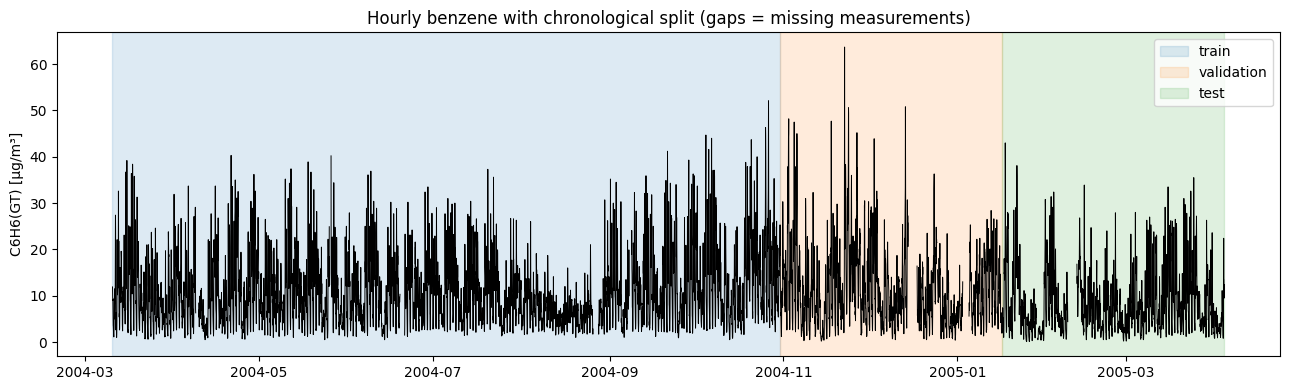

In [9]:
# Figure 1 — full target series with the chronological split drawn on it
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(df.index, df[TARGET], lw=0.7, color="k")
for part, c, lab in [(train_raw, "tab:blue", "train"), (val_raw, "tab:orange", "validation"), (test_raw, "tab:green", "test")]:
    ax.axvspan(part.index.min(), part.index.max(), color=c, alpha=0.15, label=lab)
ax.set_ylabel(f"{TARGET} [{UNIT}]"); ax.set_title("Hourly benzene with chronological split (gaps = missing measurements)")
ax.legend(loc="upper right"); plt.tight_layout(); plt.show()

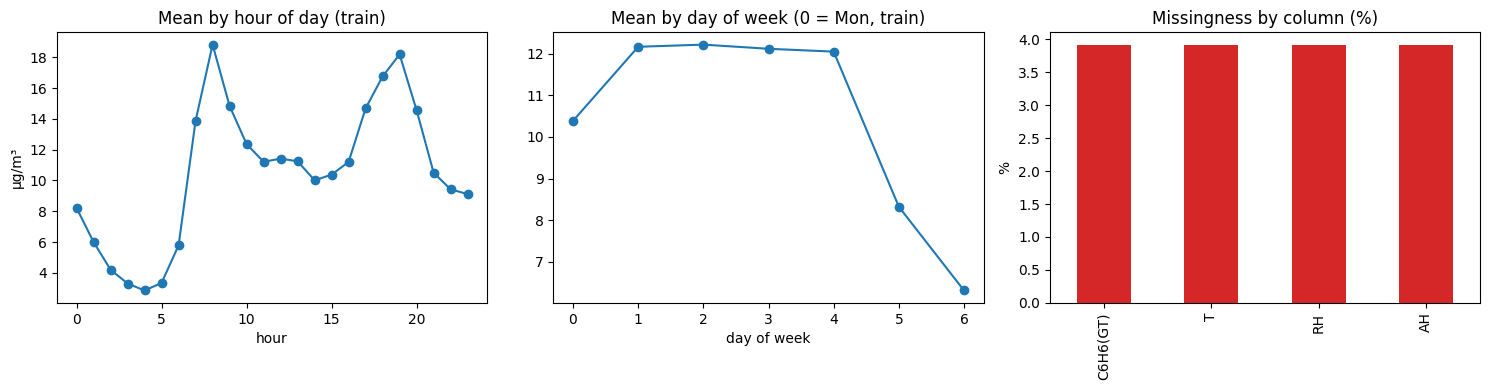

In [10]:
# Figure 2 — daily / weekly structure and missingness (computed on TRAIN only)
tr = train_raw[TARGET].dropna()
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
tr.groupby(tr.index.hour).mean().plot(ax=axes[0], marker="o"); axes[0].set_title("Mean by hour of day (train)"); axes[0].set_xlabel("hour"); axes[0].set_ylabel(UNIT)
tr.groupby(tr.index.dayofweek).mean().plot(ax=axes[1], marker="o"); axes[1].set_title("Mean by day of week (0 = Mon, train)"); axes[1].set_xlabel("day of week")
(df.isna().mean() * 100).plot.bar(ax=axes[2], color="tab:red"); axes[2].set_title("Missingness by column (%)"); axes[2].set_ylabel("%")
plt.tight_layout(); plt.show()

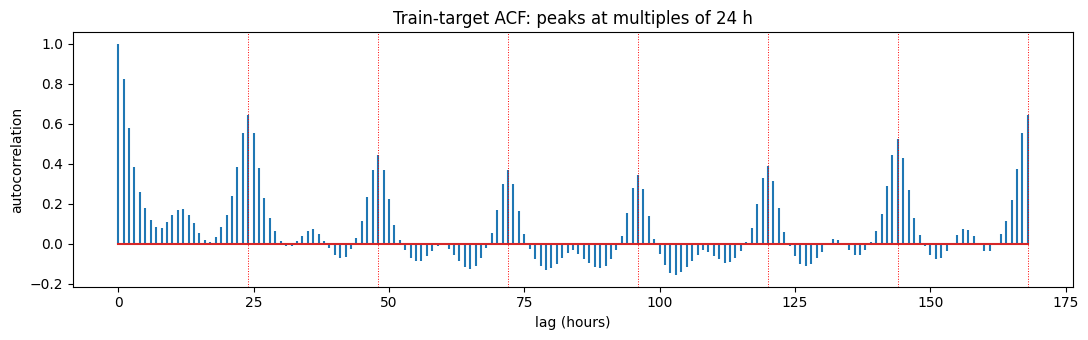

In [11]:
# Figure 3 — autocorrelation of the (causally filled) training target: justifies L = 72 and the 24 h seasonality
tr_f = train_raw[TARGET].ffill().dropna()
acf = [tr_f.autocorr(lag) for lag in range(0, 169)]
plt.figure(figsize=(11, 3.5)); plt.stem(range(169), acf, markerfmt=" ")
for k in (24, 48, 72, 96, 120, 144, 168): plt.axvline(k, color="r", ls=":", lw=0.7)
plt.xlabel("lag (hours)"); plt.ylabel("autocorrelation"); plt.title("Train-target ACF: peaks at multiples of 24 h"); plt.tight_layout(); plt.show()

## 4. Inputs, imputation, scaling and windows

**Input rule (what is allowed at forecast origin *t*):**
* history of the target up to *t* (72 hourly values);
* `T`, `RH`, `AH` **only as lagged values inside the same window (≤ t)** — we never use their values at *t+1 … t+24*, because those are not known at forecast time;
* **future-known calendar variables** of the target hour *t+24*: hour-of-day and day-of-week as sin/cos pairs (an `Xc` vector of 4 numbers).

**Imputation:** causal forward-fill *after* the split; the first value of a block may inherit the last value of the preceding block (that past observation is already known). Any NaN left at the very start of the training block is filled with the training median.
**Scaling:** `StandardScaler` fitted on the training block only (per column).
**Scoring:** windows whose *target* hour was not really observed are dropped from training, validation and test (imputed values may serve as lag inputs only).

In [12]:
def calendar_feats(index):
    """Future-known calendar variables, cyclically encoded -> (n, 4)."""
    h, d = index.hour.to_numpy(), index.dayofweek.to_numpy()
    return np.column_stack([np.sin(2*np.pi*h/24), np.cos(2*np.pi*h/24),
                            np.sin(2*np.pi*d/7),  np.cos(2*np.pi*d/7)])

def preprocess(parts_raw):
    """parts_raw: chronological list of RAW blocks. The FIRST block is the fit block (scaler/median fitted on it only)."""
    med = parts_raw[0].ffill().median()                          # fit on the first block only
    filled, prev = [], None
    for p in parts_raw:
        f = p.ffill() if prev is None else pd.concat([prev, p]).ffill().iloc[len(prev):]
        f = f.fillna(med)
        filled.append(f); prev = f.iloc[-1:]
    scaler = StandardScaler().fit(filled[0][COLS])               # fit on the first block only
    scaled = [scaler.transform(f[COLS]) for f in filled]
    return filled, scaled, scaler

def make_windows(filled, scaled, raw_part, L=LOOKBACK, h=HORIZON):
    """Windows are created INSIDE one block (never across blocks). Origin t = last element of the window."""
    n_ = len(scaled); N = n_ - L - h + 1
    origins = np.arange(L - 1, L - 1 + N)
    Xs = np.stack([scaled[o - L + 1: o + 1] for o in origins])           # (N, L, 4): target + lagged T, RH, AH
    Xc = calendar_feats(filled.index)[origins + h]                       # (N, 4): calendar of the target hour
    y = scaled[origins + h, 0]                                           # scaled target
    obs = raw_part[TARGET].notna().to_numpy()[origins + h]               # was the target really measured?
    return dict(Xs=Xs, Xc=Xc, y=y, obs=obs, t_target=filled.index[origins + h])

def keep_observed(d):
    m = d["obs"]
    return {k: v[m] for k, v in d.items()}

def to_units(a, scaler):
    return np.asarray(a) * scaler.scale_[0] + scaler.mean_[0]

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, accuracy_score, f1_score

# ---- Stage 1 (model selection): fit preprocessing on TRAIN only ----
(filled1, scaled1, scaler1) = preprocess([train_raw, val_raw])
W_tr_all = make_windows(filled1[0], scaled1[0], train_raw)
W_va_all = make_windows(filled1[1], scaled1[1], val_raw)
W_tr, W_va = keep_observed(W_tr_all), keep_observed(W_va_all)

print("Scaler fitted on TRAIN only -> mean/scale of", COLS)
print(np.round(scaler1.mean_, 3), np.round(scaler1.scale_, 3))
shapes = pd.DataFrame({
    "split": ["train", "validation"],
    "windows_total": [len(W_tr_all["y"]), len(W_va_all["y"])],
    "windows_scored": [len(W_tr["y"]), len(W_va["y"])],
    "Xs (seq input)": [W_tr["Xs"].shape, W_va["Xs"].shape],
    "Xc (calendar)": [W_tr["Xc"].shape, W_va["Xc"].shape],
    "y": [W_tr["y"].shape, W_va["y"].shape],
})
display(shapes)
print(f"Window = {LOOKBACK} h x 4 channels [{', '.join(COLS)}]; target = value {HORIZON} h after the last input hour.")

# "high-pollution event" threshold for the classification-style metrics (TRAIN data only)
EVENT_THR = float(np.nanpercentile(train_raw[TARGET], 75))
print(f"Event threshold (train 75th percentile): {EVENT_THR:.2f} {UNIT}")

Scaler fitted on TRAIN only -> mean/scale of ['C6H6(GT)', 'T', 'RH', 'AH']
[10.501 23.098 45.241  1.204] [ 7.291  7.289 16.597  0.344]


,split,windows_total,windows_scored,Xs (seq input),Xc (calendar),y
0,train,5519,5371,"(5371, 72, 4)","(5371, 4)","(5371,)"
1,validation,1776,1644,"(1644, 72, 4)","(1644, 4)","(1644,)"


Window = 72 h x 4 channels [C6H6(GT), T, RH, AH]; target = value 24 h after the last input hour.
Event threshold (train 75th percentile): 14.20 µg/m³


## 5. Metrics and bookkeeping
The task is regression, so **MAE** and **RMSE** (original units), **R²** and **MASE** are the primary metrics. **MASE = MAE / MAE of the naive (persistence) forecast on the training set only**; the denominator `MASE_SCALE` is one constant computed from the training windows, so MASE < 1 means better than naive and values are comparable across validation and test. To also report Accuracy/F1 we derive a binary *high-pollution event* (> training 75th percentile) from both the true and the predicted value. Improvement is measured against the **persistence baseline**.

In [13]:
def eval_metrics(y_true, y_pred):
    yt, yp = y_true > EVENT_THR, y_pred > EVENT_THR
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
            "R2": r2_score(y_true, y_pred),
            "MASE": mean_absolute_error(y_true, y_pred) / MASE_SCALE,
            "Event_Acc": accuracy_score(yt, yp),
            "Event_F1": f1_score(yt, yp, zero_division=0)}

def improvement(base, new):
    return 100 * (base - new) / base

def seq_flat(W):                         # flat input for the linear model
    return np.hstack([W["Xs"].reshape(len(W["y"]), -1), W["Xc"]])

## 6. Non-neural baselines (same windows, same scored instances)
1. **Persistence** — forecast = last observed value. Because h = 24 h this is *identical* to the 24-hour seasonal-naive forecast.
2. **3-day same-hour mean** — mean of the values at *t*, *t−24*, *t−48* (same hour of day as the target).
3. **Ridge regression** on the flattened window + calendar (linear model; α tuned on validation only).

In [14]:
def persistence(W, sc):    return to_units(W["Xs"][:, -1, 0], sc)
def seasonal3(W, sc):      return to_units(W["Xs"][:, [-1, -25, -49], 0].mean(axis=1), sc)

# MASE denominator: MAE of the persistence (naive) forecast on the TRAINING windows only (original units)
MASE_SCALE = mean_absolute_error(to_units(W_tr["y"], scaler1), persistence(W_tr, scaler1))
print(f"MASE denominator (naive MAE on training set): {MASE_SCALE:.3f} {UNIT}")

y_va_units = to_units(W_va["y"], scaler1)
val_preds = {"Persistence (naive)": persistence(W_va, scaler1),
             "3-day same-hour mean": seasonal3(W_va, scaler1)}

ridge_rows = []
for alpha in [0.1, 1, 10, 100, 1000, 10000]:
    t0 = time.perf_counter()
    r = Ridge(alpha=alpha).fit(seq_flat(W_tr), W_tr["y"])
    sec = time.perf_counter() - t0
    p = to_units(r.predict(seq_flat(W_va)), scaler1)
    ridge_rows.append({"alpha": alpha, "val_RMSE": eval_metrics(y_va_units, p)["RMSE"], "val_MAE": eval_metrics(y_va_units, p)["MAE"], "fit_s": sec})
ridge_grid = pd.DataFrame(ridge_rows).sort_values("val_RMSE").reset_index(drop=True)
display(ridge_grid)
best_alpha = float(ridge_grid.iloc[0]["alpha"])
ridge_val_model = Ridge(alpha=best_alpha).fit(seq_flat(W_tr), W_tr["y"])
val_preds["Ridge (linear)"] = to_units(ridge_val_model.predict(seq_flat(W_va)), scaler1)
print("Best Ridge alpha (validation only):", best_alpha)

for k, p in val_preds.items():
    print(f"{k:24s}", {m: round(v, 3) for m, v in eval_metrics(y_va_units, p).items()})

MASE denominator (naive MAE on training set): 4.165 µg/m³


,alpha,val_RMSE,val_MAE,fit_s
0,1000.0,6.820376,5.141883,0.089500
1,100.0,6.876950,5.151463,0.180603
2,10.0,6.893460,5.145071,0.102367
3,1.0,6.898738,5.149930,0.186305
4,0.1,6.899734,5.151093,0.148375
5,10000.0,6.920808,5.304579,0.086679


Best Ridge alpha (validation only): 1000.0
Persistence (naive)      {'MAE': 5.681, 'RMSE': 8.088, 'R2': 0.048, 'MASE': 1.364, 'Event_Acc': 0.756, 'Event_F1': 0.582}
3-day same-hour mean     {'MAE': 5.587, 'RMSE': 7.825, 'R2': 0.109, 'MASE': 1.342, 'Event_Acc': 0.718, 'Event_F1': 0.531}
Ridge (linear)           {'MAE': 5.142, 'RMSE': 6.82, 'R2': 0.323, 'MASE': 1.235, 'Event_Acc': 0.755, 'Event_F1': 0.573}


## 7. Neural models — MLP and 1D CNN (same inputs, horizon, loss, metrics, validation protocol)
Both receive the same two inputs: the `(72, 4)` window and the 4 calendar values of the target hour. Loss = MSE, optimizer = Adam, `shuffle=False` (chronological order preserved), early stopping on validation loss.

In [15]:
from tensorflow.keras import Model, Input
from tensorflow.keras.layers import Dense, Flatten, Concatenate, Conv1D, MaxPooling1D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

N_CH = W_tr["Xs"].shape[2]

def build_mlp(units, lr):
    seq_in, cal_in = Input(shape=(LOOKBACK, N_CH)), Input(shape=(4,))
    x = Concatenate()([Flatten()(seq_in), cal_in])
    x = Dense(units, activation="relu")(x)
    out = Dense(1)(x)
    m = Model([seq_in, cal_in], out)
    m.compile(optimizer=Adam(learning_rate=lr), loss="mse")
    return m

def build_cnn(filters, kernel_size, lr):
    seq_in, cal_in = Input(shape=(LOOKBACK, N_CH)), Input(shape=(4,))
    x = Conv1D(filters=filters, kernel_size=kernel_size, activation="relu", padding="same")(seq_in)
    x = MaxPooling1D(pool_size=2)(x)
    x = Concatenate()([Flatten()(x), cal_in])
    x = Dense(16, activation="relu")(x)
    out = Dense(1)(x)
    m = Model([seq_in, cal_in], out)
    m.compile(optimizer=Adam(learning_rate=lr), loss="mse")
    return m

def inputs(W): return [W["Xs"], W["Xc"]]

build_mlp(32, 1e-3).summary()
build_cnn(8, 3, 1e-3).summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 72, 4)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 288)       │          0 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_1       │ (None, 4)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 292)       │          0 │ flatten[0][0],    │
│ (Concatenate)       │                   │            │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 32)        │      9,376 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1)         │         33 │ dense[0][0]       │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 9,409 (36.75 KB)

 Trainable params: 9,409 (36.75 KB)

 Non-trainable params: 0 (0.00 B)

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 72, 4)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 72, 8)     │        104 │ input_layer_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 36, 8)     │          0 │ conv1d[0][0]      │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 288)       │          0 │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_3       │ (None, 4)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 292)       │          0 │ flatten_1[0][0],  │
│ (Concatenate)       │                   │            │ input_layer_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 16)        │      4,688 │ concatenate_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 1)         │         17 │ dense_2[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 4,809 (18.79 KB)

 Trainable params: 4,809 (18.79 KB)

 Non-trainable params: 0 (0.00 B)

## 8. Hyperparameter optimisation — grid search, selected on the VALIDATION set only
Selection criterion: lowest validation RMSE (original units); ties → fewer parameters.
* MLP grid: hidden units × learning rate
* CNN grid: filters × kernel size × learning rate

In [16]:
def run_grid(name, builder, grid):
    rows, histories = [], {}
    keys = list(grid)
    for combo in product(*grid.values()):
        cfg = dict(zip(keys, combo))
        tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(SEED)
        model = builder(**cfg)
        es = EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
        t0 = time.perf_counter()
        h = model.fit(inputs(W_tr), W_tr["y"], validation_data=(inputs(W_va), W_va["y"]),
                      epochs=MAX_EPOCHS, batch_size=BATCH, shuffle=False, callbacks=[es], verbose=0)
        sec = time.perf_counter() - t0
        pred = to_units(model.predict(inputs(W_va), verbose=0).ravel(), scaler1)
        m = eval_metrics(y_va_units, pred)
        rows.append({**cfg, "val_MAE": m["MAE"], "val_RMSE": m["RMSE"], "val_R2": m["R2"], "val_MASE": m["MASE"],
                     "best_epoch": int(np.argmin(h.history["val_loss"])) + 1,
                     "epochs_trained": len(h.history["loss"]), "params": model.count_params(), "train_s": sec})
        histories[combo] = h.history
        print(f"{name} {cfg} -> val RMSE {m['RMSE']:.3f}")
    res = pd.DataFrame(rows).sort_values(["val_RMSE", "params"]).reset_index(drop=True)
    best = {k: type(grid[k][0])(res.iloc[0][k]) for k in keys}
    return res, best, histories

mlp_grid = {"units": [16, 32, 64], "lr": [0.01, 0.001]}
cnn_grid = {"filters": [8, 16], "kernel_size": [3, 7], "lr": [0.01, 0.001]}

mlp_res, mlp_best, mlp_hist = run_grid("MLP", build_mlp, mlp_grid)
print("\nMLP grid results (validation):"); display(mlp_res); print("Best MLP:", mlp_best)

MLP {'units': 16, 'lr': 0.01} -> val RMSE 6.620
MLP {'units': 16, 'lr': 0.001} -> val RMSE 7.018
MLP {'units': 32, 'lr': 0.01} -> val RMSE 7.053
MLP {'units': 32, 'lr': 0.001} -> val RMSE 7.123
MLP {'units': 64, 'lr': 0.01} -> val RMSE 6.787
MLP {'units': 64, 'lr': 0.001} -> val RMSE 7.095

MLP grid results (validation):


,units,lr,val_MAE,val_RMSE,val_R2,val_MASE,best_epoch,epochs_trained,params,train_s
0,16,0.010,4.974704,6.620438,0.362097,1.194504,4,9,4705,5.869978
1,64,0.010,5.063668,6.787146,0.329567,1.215865,5,10,18817,5.414453
2,16,0.001,5.386558,7.018300,0.283123,1.293396,5,10,4705,5.200302
3,32,0.010,5.268505,7.053273,0.275960,1.265050,9,14,9409,8.217016
4,64,0.001,5.319449,7.094981,0.267372,1.277282,7,12,18817,8.129916
5,32,0.001,5.436213,7.122894,0.261596,1.305319,9,14,9409,7.925876


Best MLP: {'units': 16, 'lr': 0.01}


In [17]:
cnn_res, cnn_best, cnn_hist = run_grid("CNN", build_cnn, cnn_grid)
print("\nCNN grid results (validation):"); display(cnn_res); print("Best CNN:", cnn_best)

CNN {'filters': 8, 'kernel_size': 3, 'lr': 0.01} -> val RMSE 6.687
CNN {'filters': 8, 'kernel_size': 3, 'lr': 0.001} -> val RMSE 7.040
CNN {'filters': 8, 'kernel_size': 7, 'lr': 0.01} -> val RMSE 6.638
CNN {'filters': 8, 'kernel_size': 7, 'lr': 0.001} -> val RMSE 6.817
CNN {'filters': 16, 'kernel_size': 3, 'lr': 0.01} -> val RMSE 6.473
CNN {'filters': 16, 'kernel_size': 3, 'lr': 0.001} -> val RMSE 6.801
CNN {'filters': 16, 'kernel_size': 7, 'lr': 0.01} -> val RMSE 6.635
CNN {'filters': 16, 'kernel_size': 7, 'lr': 0.001} -> val RMSE 6.596

CNN grid results (validation):


,filters,kernel_size,lr,val_MAE,val_RMSE,val_R2,val_MASE,best_epoch,epochs_trained,params,train_s
0,16,3,0.010,4.762569,6.473449,0.390109,1.143567,7,12,9521,10.097354
1,16,7,0.001,4.913411,6.596092,0.366780,1.179786,9,14,9777,11.449086
2,16,7,0.010,4.999803,6.635117,0.359265,1.200530,8,13,9777,10.654988
3,8,7,0.010,5.045158,6.638118,0.358686,1.211421,9,14,4937,10.695286
4,8,3,0.010,5.146407,6.687253,0.349157,1.235732,4,9,4809,6.383851
5,16,3,0.001,5.070474,6.801372,0.326753,1.217500,8,13,9521,9.257438
6,8,7,0.001,5.108594,6.817343,0.323588,1.226653,9,14,4937,20.994091
7,8,3,0.001,5.213528,7.040327,0.278616,1.251849,11,16,4809,11.903047


Best CNN: {'filters': 16, 'kernel_size': 3, 'lr': 0.01}


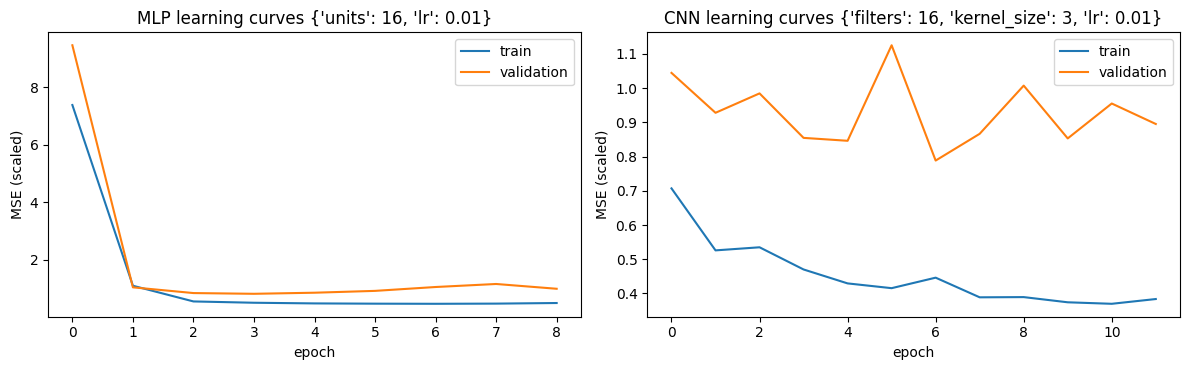

In [18]:
# learning curves of the winning configuration of each network (from the grid-search run)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, name, hist, best, grid in [(axes[0], "MLP", mlp_hist, mlp_best, mlp_grid), (axes[1], "CNN", cnn_hist, cnn_best, cnn_grid)]:
    key = tuple(best[k] for k in grid)
    h = hist[key]
    ax.plot(h["loss"], label="train"); ax.plot(h["val_loss"], label="validation")
    ax.set_title(f"{name} learning curves {best}"); ax.set_xlabel("epoch"); ax.set_ylabel("MSE (scaled)"); ax.legend()
plt.tight_layout(); plt.show()

## 9. Final refit on train + validation, then ONE evaluation on the test set
* Preprocessing (median, scaler) is **re-fitted on train+validation only**; the test block is filled and scaled with those fitted objects.
* Neural nets are retrained for `best_epoch` (chosen on validation in the grid search), with no validation split.
* Every model is scored on the identical set of observed test targets.

In [19]:
(filled2, scaled2, scaler2) = preprocess([dev_raw, test_raw])
W_dev = keep_observed(make_windows(filled2[0], scaled2[0], dev_raw))
W_te_all = make_windows(filled2[1], scaled2[1], test_raw)
W_te = keep_observed(W_te_all)
y_te_units = to_units(W_te["y"], scaler2)
print("Dev windows:", W_dev["Xs"].shape, "| Test windows (scored):", W_te["Xs"].shape, "of", len(W_te_all["y"]))
print("Final scaler (train+val only) mean/scale:", np.round(scaler2.mean_, 3), np.round(scaler2.scale_, 3))

def final_keras(builder, cfg, epochs):
    tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(SEED)
    model = builder(**cfg)
    t0 = time.perf_counter()
    model.fit(inputs(W_dev), W_dev["y"], epochs=epochs, batch_size=BATCH, shuffle=False, verbose=0)
    sec = time.perf_counter() - t0
    return model, sec, to_units(model.predict(inputs(W_te), verbose=0).ravel(), scaler2)

mlp_epochs = int(mlp_res.iloc[0]["best_epoch"]); cnn_epochs = int(cnn_res.iloc[0]["best_epoch"])
mlp_final, mlp_sec, mlp_pred = final_keras(build_mlp, mlp_best, mlp_epochs)
cnn_final, cnn_sec, cnn_pred = final_keras(build_cnn, cnn_best, cnn_epochs)

t0 = time.perf_counter()
ridge_final = Ridge(alpha=best_alpha).fit(seq_flat(W_dev), W_dev["y"])
ridge_sec = time.perf_counter() - t0
ridge_pred = to_units(ridge_final.predict(seq_flat(W_te)), scaler2)

test_preds = {"Persistence (naive)": persistence(W_te, scaler2),
              "3-day same-hour mean": seasonal3(W_te, scaler2),
              "Ridge (linear)": ridge_pred,
              "MLP": mlp_pred,
              "1D CNN": cnn_pred}

Dev windows: (7110, 72, 4) | Test windows (scored): (1691, 72, 4) of 1777
Final scaler (train+val only) mean/scale: [10.806 20.372 48.763  1.119] [ 7.702  8.208 17.39   0.369]


## 10. Comparison table (metrics, parameters, training time, baseline improvement)

In [20]:
info = {  # name: (configuration, #params, train seconds, epochs)
    "Persistence (naive)": ("last value (= 24 h seasonal naive)", 0, 0.0, 0),
    "3-day same-hour mean": ("mean of t, t-24, t-48", 0, 0.0, 0),
    "Ridge (linear)": (f"alpha={best_alpha}", seq_flat(W_dev).shape[1] + 1, ridge_sec, 0),
    "MLP": (str(mlp_best), mlp_final.count_params(), mlp_sec, mlp_epochs),
    "1D CNN": (str(cnn_best), cnn_final.count_params(), cnn_sec, cnn_epochs),
}
val_lookup = {k: eval_metrics(y_va_units, v) for k, v in val_preds.items()}
val_lookup["MLP"] = {"MAE": mlp_res.iloc[0]["val_MAE"], "RMSE": mlp_res.iloc[0]["val_RMSE"], "MASE": mlp_res.iloc[0]["val_MASE"]}
val_lookup["1D CNN"] = {"MAE": cnn_res.iloc[0]["val_MAE"], "RMSE": cnn_res.iloc[0]["val_RMSE"], "MASE": cnn_res.iloc[0]["val_MASE"]}

base = eval_metrics(y_te_units, test_preds["Persistence (naive)"])
rows = []
for name, pred in test_preds.items():
    m = eval_metrics(y_te_units, pred)
    cfg, npar, sec, ep = info[name]
    rows.append({"Model": name, "Config": cfg, "Params": npar, "Train time (s)": round(sec, 2), "Epochs": ep, "Seed": SEED,
                 "Val MAE": val_lookup[name]["MAE"], "Val RMSE": val_lookup[name]["RMSE"], "Val MASE": val_lookup[name]["MASE"],
                 "Test MAE": m["MAE"], "Test RMSE": m["RMSE"], "Test MASE": m["MASE"], "Test R2": m["R2"],
                 "Event Acc": m["Event_Acc"], "Event F1": m["Event_F1"],
                 "MAE impr. vs naive (%)": improvement(base["MAE"], m["MAE"]),
                 "RMSE impr. vs naive (%)": improvement(base["RMSE"], m["RMSE"])})
results = pd.DataFrame(rows)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
display(results.round(3))
print(f"MASE = MAE / {MASE_SCALE:.3f} (naive MAE on the training set only).")
print(f"Units: MAE/RMSE in {UNIT}. Event = benzene > {EVENT_THR:.2f} {UNIT} (train 75th percentile). "
      f"Test windows scored: {len(y_te_units)} (identical for all models).")

,Model,Config,Params,Train time (s),Epochs,Seed,Val MAE,Val RMSE,Val MASE,Test MAE,Test RMSE,Test MASE,Test R2,Event Acc,Event F1,MAE impr. vs naive (%),RMSE impr. vs naive (%)
0,Persistence (naive),last value (= 24 h seasonal naive),0,0.00,0,401003,5.681,8.088,1.364,3.826,5.681,0.919,0.202,0.842,0.484,0.000,0.000
1,3-day same-hour mean,"mean of t, t-24, t-48",0,0.00,0,401003,5.587,7.825,1.342,4.150,5.797,0.996,0.169,0.833,0.391,-8.467,-2.032
2,Ridge (linear),alpha=1000.0,293,0.15,0,401003,5.142,6.820,1.235,4.333,5.360,1.040,0.290,0.857,0.541,-13.255,5.650
3,MLP,"{'units': 16, 'lr': 0.01}",4705,2.36,4,401003,4.975,6.620,1.195,3.950,5.228,0.949,0.325,0.862,0.230,-3.257,7.987
4,1D CNN,"{'filters': 16, 'kernel_size': 3, 'lr': 0.01}",9521,6.48,7,401003,4.763,6.473,1.144,3.960,5.189,0.951,0.334,0.855,0.282,-3.506,8.665


MASE = MAE / 4.165 (naive MAE on the training set only).
Units: MAE/RMSE in µg/m³. Event = benzene > 14.20 µg/m³ (train 75th percentile). Test windows scored: 1691 (identical for all models).


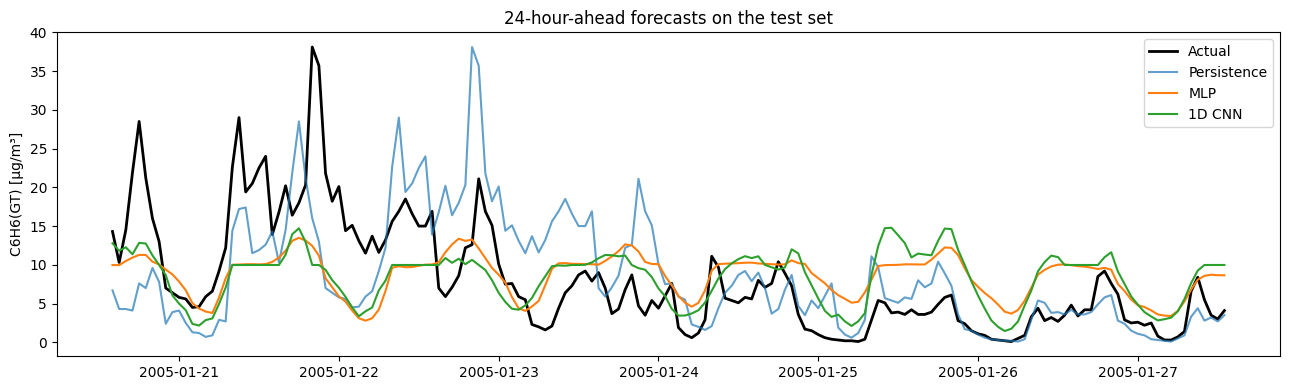

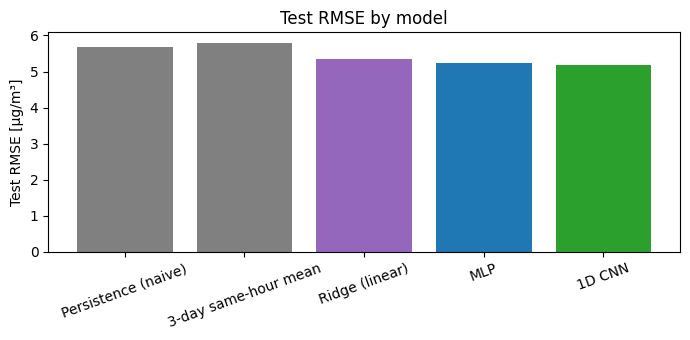

In [21]:
# Forecast visualisation (first 7 days of scored test windows) and error comparison
k = 168
plt.figure(figsize=(13, 4))
plt.plot(W_te["t_target"][:k], y_te_units[:k], "k", lw=2, label="Actual")
plt.plot(W_te["t_target"][:k], test_preds["Persistence (naive)"][:k], label="Persistence", alpha=0.7)
plt.plot(W_te["t_target"][:k], test_preds["MLP"][:k], label="MLP")
plt.plot(W_te["t_target"][:k], test_preds["1D CNN"][:k], label="1D CNN")
plt.ylabel(f"{TARGET} [{UNIT}]"); plt.title(f"{HORIZON}-hour-ahead forecasts on the test set"); plt.legend(); plt.tight_layout(); plt.show()

plt.figure(figsize=(7, 3.5))
plt.bar(results["Model"], results["Test RMSE"], color=["gray", "gray", "tab:purple", "tab:blue", "tab:green"])
plt.ylabel(f"Test RMSE [{UNIT}]"); plt.xticks(rotation=20); plt.title("Test RMSE by model"); plt.tight_layout(); plt.show()

## 11. Conclusion and unresolved risk
*(The sentence below is generated from the table; copy the numbers into your own wording.)*

In [22]:
best_row = results.iloc[results["Test RMSE"].idxmin()]
print(f"CONCLUSION: On the untouched test set the best model is {best_row['Model']} "
      f"(RMSE {best_row['Test RMSE']:.2f} {UNIT}, MAE {best_row['Test MAE']:.2f}), "
      f"{best_row['RMSE impr. vs naive (%)']:.1f}% lower RMSE and {best_row['MAE impr. vs naive (%)']:.1f}% lower MAE "
      f"than the persistence baseline for the {HORIZON}-hour horizon, selected using validation data only.")

CONCLUSION: On the untouched test set the best model is 1D CNN (RMSE 5.19 µg/m³, MAE 3.96), 8.7% lower RMSE and -3.5% lower MAE than the persistence baseline for the 24-hour horizon, selected using validation data only.


**Unresolved risk to investigate next (edit to match your results):**
The dataset covers only ~13 months, so the validation and test blocks fall in different seasons than most of the training data; benzene levels (and the sensor–pollutant relation) may drift, and the models may not generalise to a full annual cycle. In addition, long runs of missing `C6H6(GT)` values are forward-filled, which can create artificially flat lag inputs. Next step: rolling-origin (expanding-window) evaluation across several chronological folds and a sensitivity check that drops windows with long imputed stretches.